# Part 1 – Inspecting and cleaning the raw REFIT data (House 1)

Goal: check the raw House 1 data for problems, clean it with simple rules, resample to 1 minute,
and plot before / after.

Columns in the files: `Time`, `Unix` (timestamp), `Aggregate` (whole house, W) and `Appliance1`–`Appliance9`.
From the readme: **Appliance1 = fridge**, **Appliance5 = washing machine**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RAW = "../REFIT_RAW_081116/"
CLEAN = "../CLEAN_REFIT_081116/"
plt.rcParams["figure.figsize"] = (12, 4)

## 1. Load the data and have a first look

House 1 comes in two files, Part1 and Part2.

In [2]:
part1 = pd.read_csv(RAW + "RAW_House1_Part1.csv")
part2 = pd.read_csv(RAW + "RAW_House1_Part2.csv")
print("Part1:", part1.shape, " Part2:", part2.shape)
part1.head()

Part1: (4377877, 12)  Part2: (4140886, 12)


,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 14:06:17,1381327577,523,74,0,69,0,0,0,0,0,1
1,2013-10-09 14:06:31,1381327591,526,75,0,69,0,0,0,0,0,1
2,2013-10-09 14:06:46,1381327606,540,74,0,68,0,0,0,0,0,1
3,2013-10-09 14:07:01,1381327621,532,74,0,68,0,0,0,0,0,1
4,2013-10-09 14:07:15,1381327634,540,74,0,69,0,0,0,0,0,1


In [3]:
part2.head()

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2014-06-27 21:57:50,1403906269,322.0,0.0,0.0,72.0,0.0,0.0,0.0,0.0,NaN,NaN
1,2014-06-27 21:57:51,1403906271,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,1.0
2,2014-06-27 21:57:58,1403906278,329.0,NaN,0.0,NaN,NaN,0.0,0.0,0.0,30.0,NaN
3,2014-06-27 21:58:06,1403906286,322.0,0.0,0.0,71.0,NaN,NaN,NaN,0.0,30.0,NaN
4,2014-06-27 21:58:14,1403906293,320.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,30.0,NaN


In [4]:
part1.info()

<class 'pandas.DataFrame'>
RangeIndex: 4377877 entries, 0 to 4377876
Data columns (total 12 columns):
 #   Column      Dtype
---  ------      -----
 0   Time        str  
 1   Unix        int64
 2   Aggregate   int64
 3   Appliance1  int64
 4   Appliance2  int64
 5   Appliance3  int64
 6   Appliance4  int64
 7   Appliance5  int64
 8   Appliance6  int64
 9   Appliance7  int64
 10  Appliance8  int64
 11  Appliance9  int64
dtypes: int64(11), str(1)
memory usage: 400.8 MB


In [5]:
part1.describe().round(1)

,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
count,4.377877e+06,4377877.0,4377877.0,4377877.0,4377877.0,4377877.0,4377877.0,4377877.0,4377877.0,4377877.0,4377877.0
mean,1.397106e+09,484.6,19.6,17.5,29.2,8.2,9.7,10.9,1.9,6.2,79.1
std,9.204911e+06,788.1,178.9,103.3,53.2,521.7,137.9,156.0,81.7,77.6,281.1
min,1.381328e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,1.388066e+09,184.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
50%,1.398298e+09,240.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
75%,1.404914e+09,491.0,0.0,45.0,70.0,0.0,0.0,0.0,0.0,0.0,1.0
max,1.412127e+09,24000.0,69629.0,98301.0,32751.0,98301.0,32767.0,14336.0,98299.0,65549.0,65535.0


In [6]:
print("Missing values in Part1:")
print(part1.isna().sum())
print("\nMissing values in Part2:")
print(part2.isna().sum())

Missing values in Part1:


Time          0
Unix          0
Aggregate     0
Appliance1    0
Appliance2    0
Appliance3    0
Appliance4    0
Appliance5    0
Appliance6    0
Appliance7    0
Appliance8    0
Appliance9    0
dtype: int64

Missing values in Part2:
Time                0
Unix                0
Aggregate      188973
Appliance1     437890
Appliance2     459468
Appliance3     311961
Appliance4     510963
Appliance5     497223
Appliance6     342337
Appliance7     232752
Appliance8     390705
Appliance9    1911811
dtype: int64


In [7]:
for name, df in [("Part1", part1), ("Part2", part2)]:
    t = pd.to_datetime(df["Unix"], unit="s")
    print(name, "from", t.min(), "to", t.max())

Part1 from 2013-10-09 14:06:17 to 2014-10-01 01:27:07
Part2 from 2014-06-27 21:57:49 to 2015-07-10 11:56:32


**First observations**
- Part1: 4.38 M rows (Oct 2013 – Oct 2014), Part2: 4.14 M rows (Jun 2014 – Jul 2015). So the two files **overlap** in summer 2014.
- All power columns are whole watts.
- Part1 has no missing values. Part2 has many: REFIT only logs a sensor when its value changes.
- `describe()` already shows strange maximums (tens of kW on a single plug), checked below.

## 2. Quality checks

### Are the rows in time order?

In [8]:
for name, df in [("Part1", part1), ("Part2", part2)]:
    print(name, "sorted:", df["Unix"].is_monotonic_increasing,
          "| rows that go back in time:", (df["Unix"].diff() < 0).sum())

Part1 sorted: False | rows that go back in time: 1
Part2 sorted: True | rows that go back in time: 0


### Duplicates

We put both parts together (remembering which part each row came from) and count duplicates.

In [9]:
apps = [f"Appliance{i}" for i in range(1, 10)]
power_cols = ["Aggregate"] + apps

raw = pd.concat([part1.assign(part=1), part2.assign(part=2)], ignore_index=True)
print("exact duplicate rows (every column equal):", raw.duplicated(subset=["Unix"] + power_cols).sum())
print("rows sharing a timestamp:", raw.duplicated(subset="Unix").sum())

exact duplicate rows (every column equal): 884707


rows sharing a timestamp: 1211048


### Time between readings (gaps)

In [10]:
times = raw["Unix"].drop_duplicates().sort_values()
gaps = times.diff().dropna()          # seconds between two readings
print(gaps.describe().round(1))
print("\ngaps > 30 s:", (gaps > 30).sum())
print("gaps > 5 min:", (gaps > 300).sum())
print("gaps > 1 hour:", (gaps > 3600).sum())
print("longest gap: %.1f days" % (gaps.max() / 86400))

count    7307714.0
mean           7.6
std         1394.7
min            1.0
25%            4.0
50%            7.0
75%            8.0
max      3594414.0
Name: Unix, dtype: float64

gaps > 30 s: 4836
gaps > 5 min: 390
gaps > 1 hour: 21
longest gap: 41.6 days


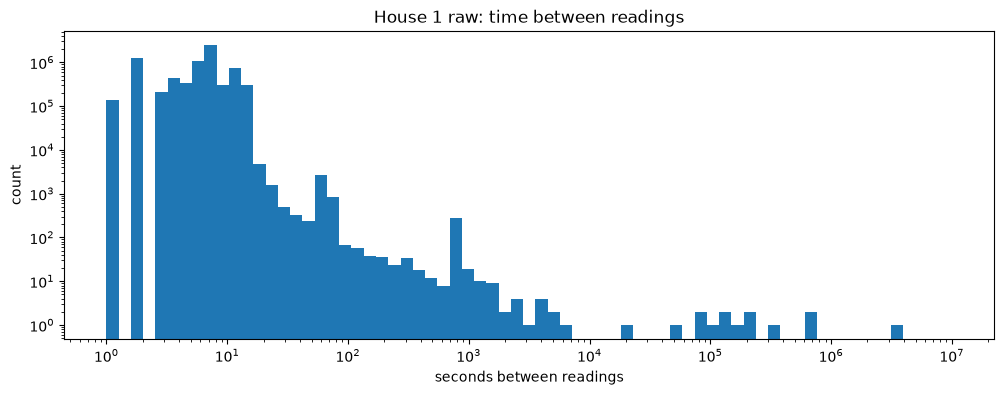

In [11]:
plt.hist(gaps, bins=np.logspace(0, 7, 70))
plt.xscale("log"); plt.yscale("log")
plt.xlabel("seconds between readings"); plt.ylabel("count")
plt.title("House 1 raw: time between readings")
plt.show()

### Impossible values

- A UK house has a 100 A main fuse × 230 V ≈ **23 kW**, so a higher aggregate is impossible.
- A normal plug (13 A) gives about 3 kW. REFIT's own readme treats plug values above **4 kW** as errors.

In [12]:
print("negative values:", (raw[power_cols] < 0).sum().sum())
print("aggregate above 23 kW:", (raw["Aggregate"] > 23000).sum(), "| max:", raw["Aggregate"].max())
print("\nappliance readings above 4 kW:")
print((raw[apps] > 4000).sum())
print("\nlargest value per appliance:")
print(raw[apps].max())

negative values: 0
aggregate above 23 kW: 77 | max: 29159.0

appliance readings above 4 kW:
Appliance1     846
Appliance2      40
Appliance3     118
Appliance4    2085
Appliance5     221
Appliance6      36
Appliance7     374
Appliance8     179
Appliance9      50
dtype: int64

largest value per appliance:


Appliance1    76677.0
Appliance2    98301.0
Appliance3    73725.0
Appliance4    98301.0
Appliance5    73725.0
Appliance6    37610.0
Appliance7    98299.0
Appliance8    98301.0
Appliance9    65535.0
dtype: float64


**Summary of the checks**
- **Order:** Part1 has 1 row out of time order, Part2 none. We will sort anyway.
- **Duplicates:** ~885,000 rows are exact copies, and ~1.2 M rows share a timestamp (this includes the Part1/Part2 overlap).
- **Gaps:** the median time between readings is 7 s (as expected), but there are 390 gaps over 5 minutes, 21 over an hour,
  and one of **41.6 days** (Feb 2014, also mentioned in the readme).
- **Impossible values:** 77 aggregate readings above 23 kW and about 3,900 plug readings above 4 kW, up to 98,301 W.
  The value **65,535** is the largest number a 16-bit sensor can store: a typical glitch.

## 3. A timing problem: Part1 is in UK local time

When we compare the raw data with the **official cleaned data** for the same day, summer days do not line
up. Below: a summer day and a winter day, raw (time as written in the file) vs official.

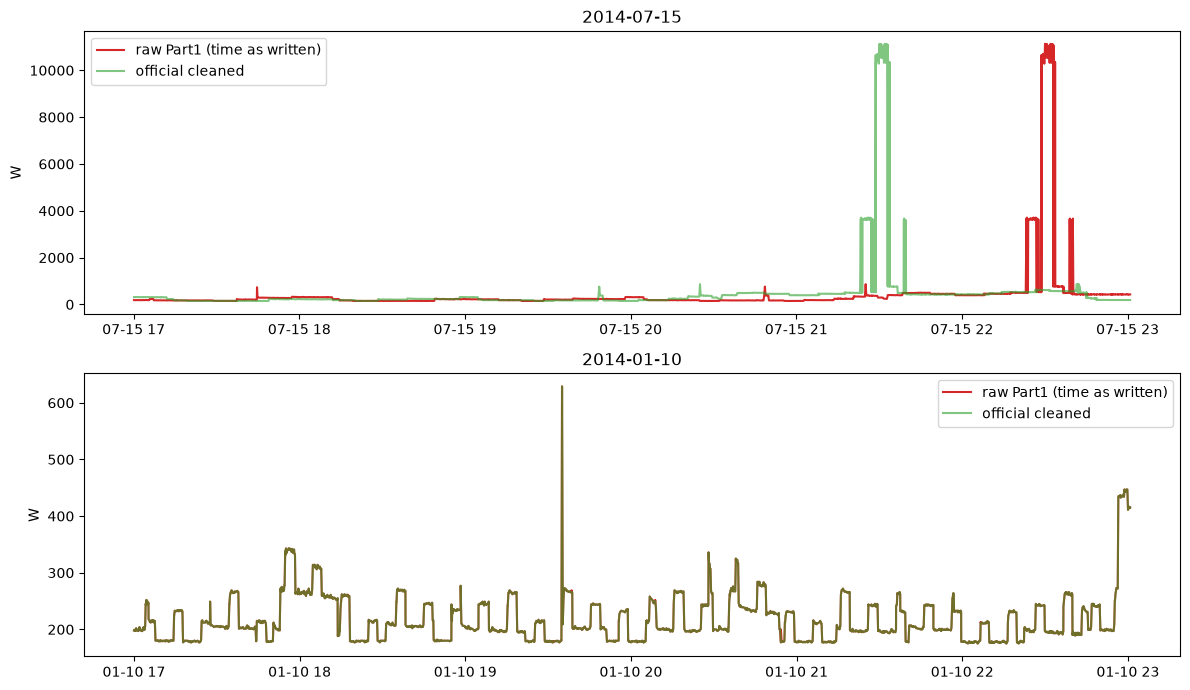

In [13]:
official = pd.read_csv(CLEAN + "CLEAN_House1.csv", usecols=["Unix", "Aggregate"])
official.index = pd.to_datetime(official["Unix"], unit="s", utc=True)
official = official.sort_index()

raw["time_in_file"] = pd.to_datetime(raw["Unix"], unit="s", utc=True)
p1 = raw[raw["part"] == 1].set_index("time_in_file").sort_index()

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, day in zip(axes, ["2014-07-15", "2014-01-10"]):
    start, end = day + " 17:00", day + " 23:00"
    ax.plot(p1.loc[start:end, "Aggregate"], label="raw Part1 (time as written)", color="tab:red")
    ax.plot(official.loc[start:end, "Aggregate"], label="official cleaned", color="tab:green", alpha=0.6)
    ax.set_title(day); ax.set_ylabel("W"); ax.legend()
plt.tight_layout(); plt.show()

In **summer** the raw line is exactly **1 hour late**, in **winter** the two match. That is the UK clock
change: UK summer time is UTC+1, winter time is UTC. So Part1's timestamps are **UK local time**, not UTC.
(Checking Part2 the same way shows it is already in UTC.)

**Fix:** read Part1's times as `Europe/London` local time and convert them to UTC. In October the clock
goes back and 01:00–02:00 happens twice, so readings in that hour cannot be placed; they are dropped.

In [14]:
local = raw["time_in_file"].dt.tz_localize(None).dt.tz_localize("Europe/London", ambiguous="NaT", nonexistent="NaT")
raw["ts"] = raw["time_in_file"].where(raw["part"] == 2, local.dt.tz_convert("UTC"))
print("rows in the clock-change hour (dropped):", raw["ts"].isna().sum())

rows in the clock-change hour (dropped): 1199


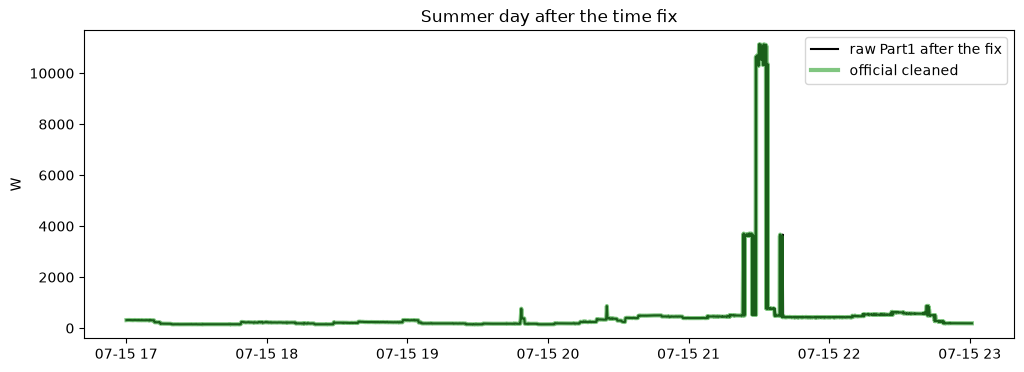

In [15]:
p1 = raw[raw["part"] == 1].dropna(subset=["ts"]).set_index("ts").sort_index()
start, end = "2014-07-15 17:00", "2014-07-15 23:00"
plt.plot(p1.loc[start:end, "Aggregate"], label="raw Part1 after the fix", color="black")
plt.plot(official.loc[start:end, "Aggregate"], label="official cleaned", color="tab:green", alpha=0.6, lw=3)
plt.title("Summer day after the time fix"); plt.ylabel("W"); plt.legend(); plt.show()

### Part1 and Part2 overlap

The two files cover some of the same period. Which one is better there?

In [16]:
part1_end = raw.loc[raw["part"] == 1, "ts"].max()
overlap = (raw["part"] == 2) & (raw["ts"] <= part1_end)
print("Part1 ends:", part1_end)
print("Part2 rows inside Part1's period:", overlap.sum())
print("missing Aggregate in that period -> Part2: %.1f%%" % (100 * raw.loc[overlap, "Aggregate"].isna().mean()),
      "| Part1: %.1f%%" % (100 * raw.loc[raw["part"] == 1, "Aggregate"].isna().mean()))

Part1 ends: 2014-10-01 00:27:07+00:00
Part2 rows inside Part1's period: 944950
missing Aggregate in that period -> Part2: 5.8% | Part1: 0.0%


Part1 is complete there, so in the overlap we **keep Part1**.

## 4. Cleaning

The rules, in order:

1. drop rows whose time could not be placed (clock-change hour)
2. overlap: keep Part1
3. impossible values (negative, aggregate > 23 kW, appliance > 4 kW) → missing (NaN)
4. sort by time
5. duplicate timestamps → keep the first row
6. resample to **1 minute** (mean of the readings in each minute)
7. frozen sensor (same non-zero value for 30+ minutes) → missing
8. gaps of up to 5 minutes → interpolate; longer gaps → mark as **outage** and leave empty

In [17]:
df = raw.dropna(subset=["ts"])                                   # 1
df = df[~((df["part"] == 2) & (df["ts"] <= part1_end))].copy()  # 2

df[power_cols] = df[power_cols].mask(df[power_cols] < 0)         # 3
df["Aggregate"] = df["Aggregate"].mask(df["Aggregate"] > 23000)
df[apps] = df[apps].mask(df[apps] > 4000)

df = df.sort_values("ts", kind="stable")                         # 4 (stable: keeps file order for equal times)
df = df.drop_duplicates(subset="ts", keep="first")               # 5

house1 = df.set_index("ts")[power_cols].resample("1min").mean()  # 6
print("rows after cleaning steps 1-5:", len(df), "| 1-minute rows:", len(house1))
house1.head()

rows after cleaning steps 1-5: 6556603 | 1-minute rows: 920091


,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
ts,,,,,,,,,,
2013-10-09 13:06:00+00:00,529.666667,74.333333,0.0,68.666667,0.0,0.0,0.0,0.0,0.0,1.0
2013-10-09 13:07:00+00:00,543.875000,73.875000,0.0,68.750000,0.0,0.0,0.0,0.0,0.0,1.0
2013-10-09 13:08:00+00:00,572.444444,73.111111,0.0,46.555556,0.0,0.0,0.0,0.0,0.0,1.0
2013-10-09 13:09:00+00:00,638.300000,72.800000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,1.0
2013-10-09 13:10:00+00:00,800.200000,72.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,1.0


Step 7 and 8 need two small helper functions:
`run_length` tells, for every minute, how long the run of missing (or frozen) minutes around it is.

In [18]:
def run_length(mask):
    """For every row: how long is the run of equal True/False values it belongs to."""
    run_id = (mask != mask.shift()).cumsum()
    return mask.groupby(run_id).transform("size")


def frozen(s, minutes=30):
    """True where a sensor repeats exactly the same non-zero value for 30+ minutes.
    Small gaps (<= 5 min) inside the flat line are bridged with the last known value."""
    last = s.ffill(limit=5)
    same = (last.diff() == 0) & (last > 30)
    return same & (run_length(same) >= minutes) & s.notna()


def fill_short_gaps(s, max_gap=5):
    """Interpolate gaps of up to 5 minutes; longer gaps stay empty."""
    missing = s.isna()
    short = missing & (run_length(missing) <= max_gap)
    return s.where(~short, s.interpolate(limit_area="inside"))

In [19]:
frozen_minutes = pd.Series(False, index=house1.index)
for col in power_cols:                                           # 7
    f = frozen(house1[col])
    house1.loc[f, col] = np.nan
    frozen_minutes = frozen_minutes | f
print("minutes with a frozen sensor:", frozen_minutes.sum())

missing = house1["Aggregate"].isna()                             # 8
house1["outage"] = missing & (run_length(missing) > 5)
house1["interpolated"] = missing & ~house1["outage"]
for col in power_cols:
    house1[col] = fill_short_gaps(house1[col])

print("minutes interpolated:", house1["interpolated"].sum())
print("minutes marked as outage: %d (%.1f%%)" % (house1["outage"].sum(), 100 * house1["outage"].mean()))

minutes with a frozen sensor: 9588


minutes interpolated: 759
minutes marked as outage: 122505 (13.3%)


In [20]:
# list of outages
out = house1["outage"]
outage_id = (out != out.shift()).cumsum()[out]
outages = out[out].groupby(outage_id).agg(start=lambda s: s.index[0], minutes="size")
print("number of outages:", len(outages), "| of which >= 1 hour:", (outages["minutes"] >= 60).sum())
outages.sort_values("minutes", ascending=False).head(10)

number of outages: 420 | of which >= 1 hour: 33


,start,minutes
outage,,
544,2014-01-24 01:57:00+00:00,59906
794,2015-05-10 23:37:00+00:00,12453
812,2015-06-10 13:20:00+00:00,10819
694,2014-08-30 11:01:00+00:00,7172
780,2015-04-03 01:44:00+00:00,6274
772,2015-03-22 08:16:00+00:00,3307
798,2015-05-24 10:10:00+00:00,2999
728,2014-10-27 00:06:00+00:00,2260
778,2015-03-31 04:23:00+00:00,2163


An example of a frozen sensor: the longest flat line in the aggregate.

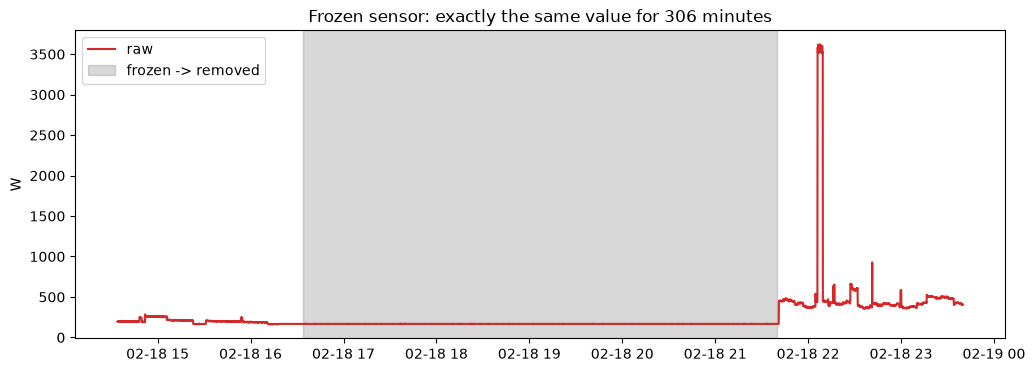

In [21]:
f = frozen(df.set_index("ts")["Aggregate"].resample("1min").mean())
fid = (f != f.shift()).cumsum()[f]
longest = f[f].groupby(fid).size().idxmax()
start, end = f[f][fid == longest].index[[0, -1]]
window = df.set_index("ts").loc[start - pd.Timedelta("2h"):end + pd.Timedelta("2h"), "Aggregate"]

plt.plot(window, color="tab:red", label="raw")
plt.axvspan(start, end, color="grey", alpha=0.3, label="frozen -> removed")
plt.title("Frozen sensor: exactly the same value for %d minutes" % ((end - start).total_seconds() / 60))
plt.ylabel("W"); plt.legend(); plt.show()

## 5. Before / after plots

Coverage over the whole period: raw readings per day, and the cleaned aggregate with outages in red.

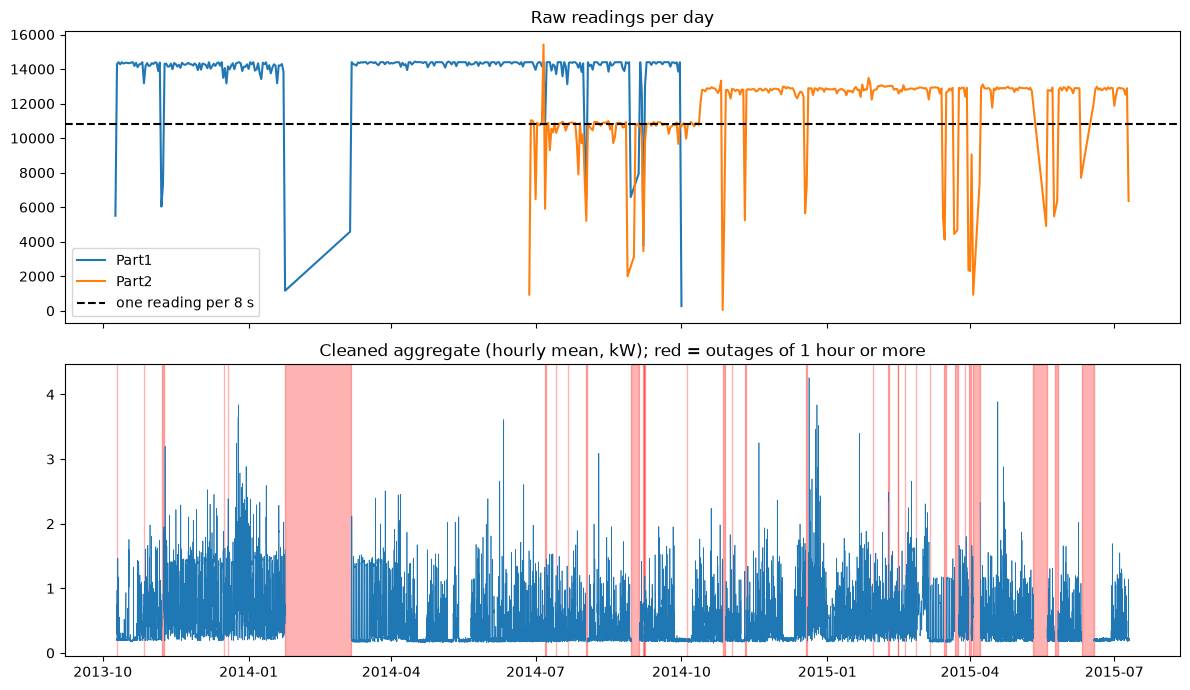

In [22]:
per_day = raw.dropna(subset=["ts"]).groupby([raw["part"], raw["ts"].dt.floor("D")]).size()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for part in [1, 2]:
    axes[0].plot(per_day.loc[part], label=f"Part{part}")
axes[0].axhline(86400 / 8, color="black", ls="--", label="one reading per 8 s")
axes[0].set_title("Raw readings per day"); axes[0].legend()

axes[1].plot(house1["Aggregate"].resample("1h").mean() / 1000, lw=0.5)
for _, o in outages[outages["minutes"] >= 60].iterrows():
    axes[1].axvspan(o["start"], o["start"] + pd.Timedelta(minutes=o["minutes"]), color="red", alpha=0.3)
axes[1].set_title("Cleaned aggregate (hourly mean, kW); red = outages of 1 hour or more")
plt.tight_layout(); plt.savefig("../figures/part1_coverage.png", dpi=110); plt.show()

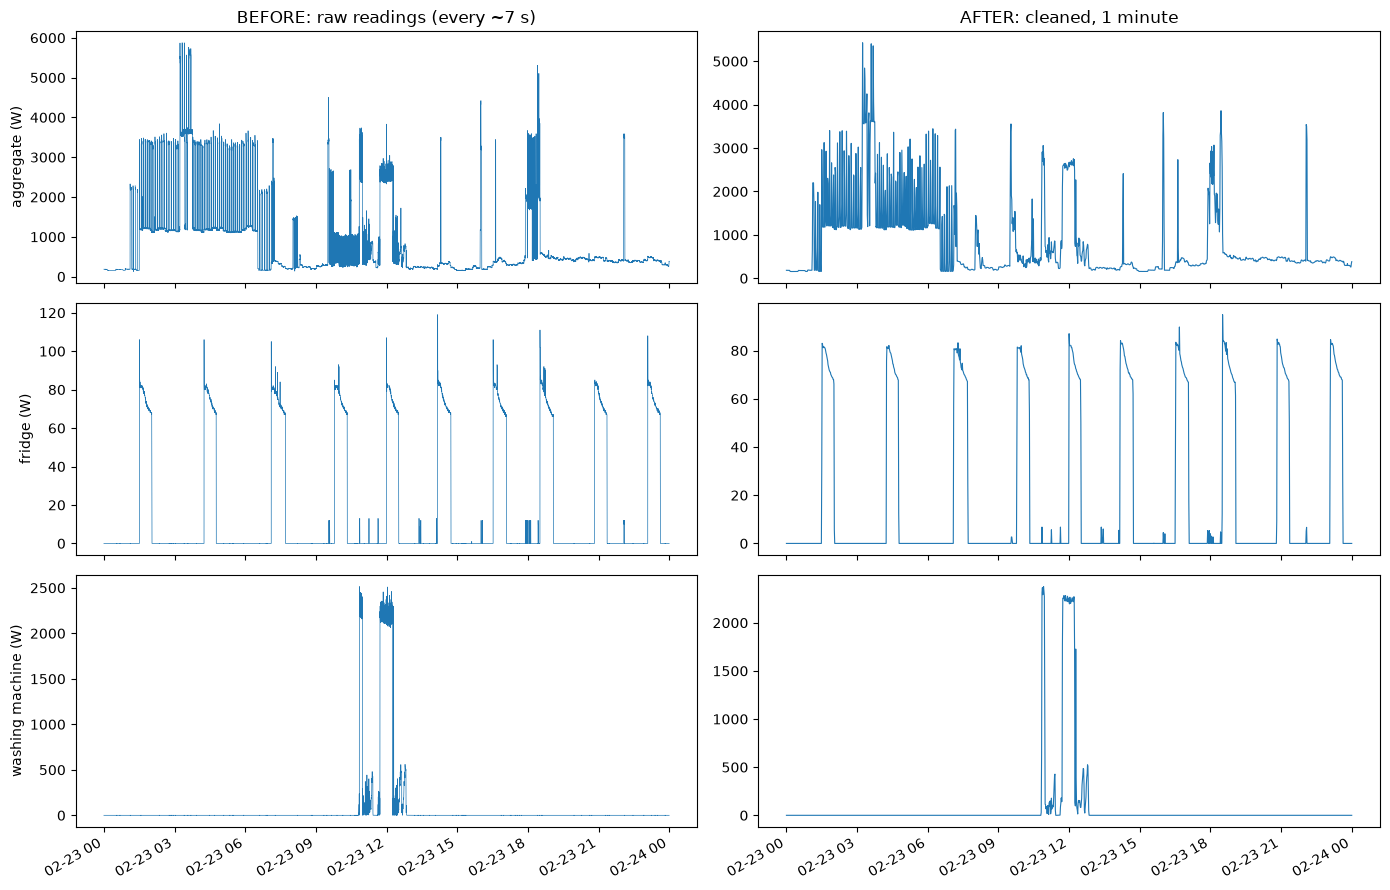

In [23]:
# one day with a washing-machine run: raw readings (left) and cleaned 1-minute data (right)
day = house1["Appliance5"].resample("1D").sum().idxmax()
raw_day = df.set_index("ts").loc[day:day + pd.Timedelta("1D")]
clean_day = house1.loc[day:day + pd.Timedelta("1D")]

fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)
for row, (col, name) in enumerate([("Aggregate", "aggregate"), ("Appliance1", "fridge"), ("Appliance5", "washing machine")]):
    axes[row, 0].plot(raw_day[col], lw=0.5)
    axes[row, 1].plot(clean_day[col], lw=0.8)
    axes[row, 0].set_ylabel(name + " (W)")
axes[0, 0].set_title("BEFORE: raw readings (every ~7 s)")
axes[0, 1].set_title("AFTER: cleaned, 1 minute")
fig.autofmt_xdate(); plt.tight_layout(); plt.savefig("../figures/part1_before_after.png", dpi=110); plt.show()

On the left: every raw reading. On the right: cleaned 1-minute data. Noise and spikes are reduced, but the fridge
cycling (~80 W) and the washing machine's heating block (~2.2 kW) are still clearly visible, so the cleaning keeps the
appliance patterns we need later.

## 6. Sanity check against the official cleaned data

In [24]:
official_1min = official["Aggregate"].resample("1min").mean()
both = pd.concat([house1["Aggregate"].where(~house1["outage"]), official_1min], axis=1, keys=["ours", "official"]).dropna()
print("minutes compared:", len(both))
print("correlation: %.3f" % both["ours"].corr(both["official"]))
print("mean absolute difference: %.1f W" % (both["ours"] - both["official"]).abs().mean())

minutes compared: 796710
correlation: 0.999
mean absolute difference: 4.2 W


Our cleaned data matches the official cleaned data very closely (correlation 0.999, average difference about 4 W).
This shows the cleaning, including the time fix, is right.

## Summary of Part 1

| Problem found | What we did |
|---|---|
| Part1 timestamps in UK local time (1 h off in summer) | converted to UTC |
| Part1 and Part2 overlap (~945,000 rows) | kept Part1 (no missing values) |
| ~885,000 exact duplicate rows, more rows with the same timestamp | kept the first row |
| impossible values (up to 98 kW on a plug, 29 kW aggregate) | set to missing |
| frozen sensors (same value for hours) | set to missing (9,588 minutes) |
| short gaps (≤ 5 min) | interpolated (759 minutes) |
| long gaps (13.3 % of minutes, 420 outages, longest 6 weeks) | marked as outage, **not filled** |

We don't fill long gaps because that would mean inventing hours or weeks of data.

In [25]:
house1.to_pickle("../data/house1_clean_1min.pkl")